## 目标检测

这是 [AI for Beginners Curriculum](http://aka.ms/ai-beginners) 中的一个笔记本


![图像算法](https://cdn-images-1.medium.com/max/840/1*Hz6t-tokG1niaUfmcysusw.jpeg)


## 对象检测的简单方法

* 将图像分割成多个小块
* 对每个小块运行 CNN 图像分类器
* 选择激活值超过阈值的小块


In [11]:
import cv2
from tensorflow import keras
import numpy as np
import matplotlib.pyplot as plt
import os

让我们读取示例图像进行操作，并将其填充为正方形尺寸：


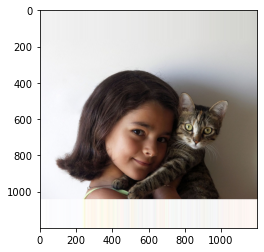

In [19]:
img = cv2.imread('images/1200px-Girl_and_cat.jpg')
img = cv2.cvtColor(img,cv2.COLOR_BGR2RGB)
img = np.pad(img,((158,158),(0,0),(0,0)),mode='edge')
plt.imshow(img)

我们将使用预训练的VGG-16 CNN：


In [14]:
vgg = keras.applications.vgg16.VGG16(weights='imagenet')

让我们定义一个函数来预测图像中出现猫的概率。由于 ImageNet 包含多个猫类，其索引从 281 到 294，我们将把这些类别的概率相加以获得整体的“猫”概率：


In [15]:
def predict(img):
  im = cv2.resize(img,(224,224))
  im = keras.applications.vgg16.preprocess_input(im)
  pr = vgg.predict(np.expand_dims(im,axis=0))[0]
  return np.sum(pr[281:294]) # we know that VGG classes for cats are from 281 to 294

predict(img)

0.61825

下一个函数将构建一个概率热图，将图像划分为 $n\times n$ 方块：


In [20]:
def predict_map(img,n):
  dx = img.shape[0] // n
  res = np.zeros((n,n),dtype=np.float32)
  for i in range(n):
    for j in range(n):
      im = img[dx*i:dx*(i+1),dx*j:dx*(j+1)]
      r = predict(im)
      res[i,j] = r
  return res

fig,ax = plt.subplots(1,2,figsize=(15,5))
ax[1].imshow(img)
ax[0].imshow(predict_map(img,10))

## 检测简单对象

为了更精确地定位边界框，我们需要运行**回归模型**来预测边界框的坐标。让我们从一个简单的例子开始：在32x32的图像中检测黑色矩形。这个想法和部分代码借鉴自[这篇博客文章](https://towardsdatascience.com/object-detection-with-neural-networks-a4e2c46b4491)。

以下函数将生成一组样本图像：


In [113]:
def generate_images(num_imgs, img_size=8, min_object_size = 1, max_object_size = 4):
    bboxes = np.zeros((num_imgs, 4))
    imgs = np.zeros((num_imgs, img_size, img_size))  # set background to 0

    for i_img in range(num_imgs):
        w, h = np.random.randint(min_object_size, max_object_size, size=2)
        x = np.random.randint(0, img_size - w)
        y = np.random.randint(0, img_size - h)
        imgs[i_img, x:x+w, y:y+h] = 1.  # set rectangle to 1
        bboxes[i_img] = [x, y, w, h]
    return imgs, bboxes

imgs, bboxes = generate_images(100000)
print(f"Images shape = {imgs.shape}")
print(f"BBoxes shape = {bboxes.shape}")

Images shape = (100000, 8, 8)
BBoxes shape = (100000, 4)


为了使网络的输出在范围 [0;1] 内，我们将用图像大小除以 `bboxes`：


In [114]:
bb = bboxes/8.0
bb[0]

array([0.   , 0.25 , 0.125, 0.25 ])

在我们的简单示例中，我们将使用密集神经网络。在现实生活中，当对象具有更复杂的形状时，使用卷积神经网络（CNN）来完成这样的任务肯定是有意义的。我们将使用随机梯度下降优化器和均方误差（MSE）作为指标，因为我们的任务是**回归**。


In [144]:
model = keras.Sequential([
    keras.layers.Flatten(input_shape=(8,8)),
    keras.layers.Dense(200, activation='relu'),
    keras.layers.Dropout(0.2),
    keras.layers.Dense(4)
])
model.compile('sgd','mse')
model.summary()

Model: "sequential_25"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 flatten_24 (Flatten)        (None, 64)                0         
                                                                 
 dense_50 (Dense)            (None, 200)               13000     
                                                                 
 dropout_3 (Dropout)         (None, 200)               0         
                                                                 
 dense_51 (Dense)            (None, 4)                 804       
                                                                 
Total params: 13,804
Trainable params: 13,804
Non-trainable params: 0
_________________________________________________________________


让我们训练我们的网络。我们还将对输入数据进行归一化处理（通过减去均值并除以标准差），以获得稍好的性能。


In [145]:
imgs_norm = (imgs-np.mean(imgs))/np.std(imgs)
model.fit(imgs_norm,bb,epochs=30)

Epoch 1/30
3125/3125 [==============================] - 6s 2ms/step - loss: 0.0562
Epoch 2/30
3125/3125 [==============================] - 5s 2ms/step - loss: 0.0131
Epoch 3/30
3125/3125 [==============================] - 5s 1ms/step - loss: 0.0076
Epoch 4/30
3125/3125 [==============================] - 5s 2ms/step - loss: 0.0058
Epoch 5/30
3125/3125 [==============================] - 5s 2ms/step - loss: 0.0050
Epoch 6/30
3125/3125 [==============================] - 5s 2ms/step - loss: 0.0044
Epoch 7/30
3125/3125 [==============================] - 5s 2ms/step - loss: 0.0041
Epoch 8/30
3125/3125 [==============================] - 5s 2ms/step - loss: 0.0038
Epoch 9/30
3125/3125 [==============================] - 5s 2ms/step - loss: 0.0036
Epoch 10/30
3125/3125 [==============================] - 6s 2ms/step - loss: 0.0034
Epoch 11/30
3125/3125 [==============================] - 8s 3ms/step - loss: 0.0033
Epoch 12/30
3125/3125 [==============================] - 8s 3ms/step - loss: 0.0031
E

我们似乎有相对较好的损失，让我们看看它如何转化为更具体的指标，例如mAP。首先，让我们定义两个边界框之间的IOU指标：


In [146]:
def IOU(bbox1, bbox2):
    '''Calculate overlap between two bounding boxes [x, y, w, h] as the area of intersection over the area of unity'''
    x1, y1, w1, h1 = bbox1[0], bbox1[1], bbox1[2], bbox1[3]
    x2, y2, w2, h2 = bbox2[0], bbox2[1], bbox2[2], bbox2[3]
    w_I = min(x1 + w1, x2 + w2) - max(x1, x2)
    h_I = min(y1 + h1, y2 + h2) - max(y1, y2)
    if w_I <= 0 or h_I <= 0:  # no overlap
        return 0.
    I = w_I * h_I
    U = w1 * h1 + w2 * h2 - I
    return I / U

我们现在将生成500张测试图像，并绘制其中前5张以可视化我们的准确性。我们还将打印出IOU指标。


pred=[3.7325673 3.6551285 2.0126944 1.030895 ],act=[4. 4. 2. 1.], IOU=0.41607480412565545
pred=[2.3762555 3.755858  1.1647941 1.0540264],act=[2. 4. 1. 1.], IOU=0.2932611042051458
pred=[-0.04900682 -0.10628867  2.7881489   1.027148  ],act=[0. 0. 3. 1.], IOU=0.7548650953478908
pred=[0.96806276 4.267275   1.3179774  1.1021365 ],act=[0. 5. 1. 1.], IOU=0.004833667961256898
pred=[2.157959   0.94667876 2.7568097  0.96259   ],act=[2. 1. 3. 1.], IOU=0.7965311752734529


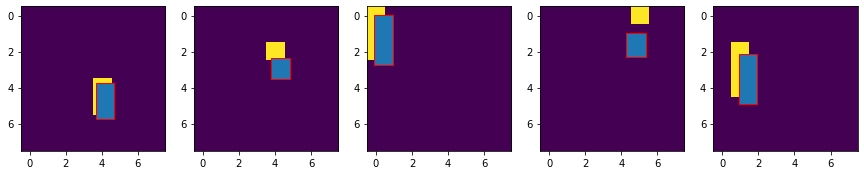

In [149]:
import matplotlib

test_imgs, test_bboxes = generate_images(500)
bb_res = model.predict((test_imgs-np.mean(imgs))/np.std(imgs))*8

plt.figure(figsize=(15,5))
for i in range(5):
    print(f"pred={bb_res[i]},act={test_bboxes[i]}, IOU={IOU(bb_res[i],test_bboxes[i])}")
    plt.subplot(1,5,i+1)
    plt.imshow(test_imgs[i])
    plt.gca().add_patch(matplotlib.patches.Rectangle((bb_res[i,1],bb_res[i,0]),bb_res[i,3],bb_res[i,2],ec='r'))
    #plt.annotate('IOU: {:.2f}'.format(IOU(bb_res[i],test_bboxes[i])),(bb_res[i,1],bb_res[i,0]+bb_res[i,3]),color='y')


现在要计算所有案例的平均精度，我们只需要遍历所有测试样本，计算IoU，然后计算平均值：


In [151]:
np.array([IOU(a,b) for a,b in zip(test_bboxes,bb_res)]).mean()

0.7150587956049862

## 实际物体检测

实际的物体检测算法更加复杂。如果你想深入了解RetinaNet的实现，我们建议你参考[Keras关于使用RetinaNet进行物体检测的教程](https://keras.io/examples/vision/retinanet/)。如果你只是想训练一个物体检测模型，可以使用[Keras RetinaNet库](https://github.com/fizyr/keras-retinanet)。



---

**免责声明**：  
本文档使用AI翻译服务 [Co-op Translator](https://github.com/Azure/co-op-translator) 进行翻译。尽管我们努力确保翻译的准确性，但请注意，自动翻译可能包含错误或不准确之处。应以原始语言的文档作为权威来源。对于关键信息，建议使用专业人工翻译。我们不对因使用此翻译而产生的任何误解或误读承担责任。
